# Seasonal Trends in ARCHER2 Node-Hour Usage

This notebook looks at how workload changes across seasons for the busiest software on ARCHER2.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

data_path = Path("../data/archer2_HPC_data_without_overall_and_aOut.csv")
hpc_data = pd.read_csv(data_path)

# Clean the data
hpc_data["Year"] = pd.to_numeric(hpc_data["Year"], errors="coerce")
hpc_data["Month"] = pd.to_numeric(hpc_data["Month"], errors="coerce")
hpc_data["Nodeh"] = pd.to_numeric(hpc_data["Nodeh"], errors="coerce").fillna(0)

season_order = ["Winter", "Spring", "Summer", "Autumn"]
hpc_data["Season"] = pd.Categorical(
    hpc_data["Season"],
    categories=season_order,
    ordered=True
)

print("Dataset loaded:", hpc_data.shape)
print(hpc_data.head())

Dataset loaded: (2834, 17)
   Unnamed: 0       Software   Min     Q1  Median      Q3      Max    Jobs  \
0           0           VASP   1.0  512.0   512.0  1792.0  23040.0  106683   
1           1        Unknown   1.0  512.0  1920.0  6400.0  99104.0  733058   
2           2  Met Office UM  26.0  576.0  1296.0  6165.0   7320.0   25300   
3           3       FHI aims   1.0  512.0  1024.0  1024.0   8192.0   88893   
4           4        GROMACS   1.0  512.0  1024.0  1024.0   2560.0   27422   

      Nodeh  PercentUse  Users  Projects  Year  Month  Season  kWh  \
0  886382.6        20.1  139.0      14.0  2026      1  Winter  NaN   
1  794869.1        18.0  512.0      94.0  2026      1  Winter  NaN   
2  418021.1         9.5   43.0       2.0  2026      1  Winter  NaN   
3  171081.4         3.9   33.0       6.0  2026      1  Winter  NaN   
4  165316.9         3.7   40.0       7.0  2026      1  Winter  NaN   

   PercentEnergy  
0            NaN  
1            NaN  
2            NaN  
3      

In [7]:
# Find the top 5 software by total node-hours
overall_top5 = (
    hpc_data.groupby("Software")["Nodeh"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 software overall:")
print(overall_top5)

top_names = overall_top5.index.tolist()
filtered = hpc_data[hpc_data["Software"].isin(top_names)]

Top 5 software overall:
Software
VASP             38813941.0
Unknown          34127812.1
Met Office UM    12963665.3
GROMACS           9546313.3
CP2K              9091777.7
Name: Nodeh, dtype: float64


In [8]:
# Aggregate seasonal totals for the selected software
seasonal_trend = (
    filtered.groupby(["Season", "Software"], observed=True)["Nodeh"]
    .sum()
    .reset_index()
)

pivot_df = seasonal_trend.pivot_table(
    index="Season",
    columns="Software",
    values="Nodeh",
    aggfunc="sum",
    observed=True
).fillna(0)

pivot_df = pivot_df.reindex(season_order)
print(pivot_df)

Software       CP2K    GROMACS  Met Office UM     Unknown        VASP
Season                                                               
Winter    2019118.6  2415683.7      3717394.6   8266670.4  10541849.4
Spring    2608972.6  2594441.3      3438179.1  10406381.5  11793326.6
Summer    2569194.1  2351719.2      3005815.5   8901804.0   9198018.8
Autumn    1894492.4  2184469.1      2802276.1   6552956.2   7280746.2


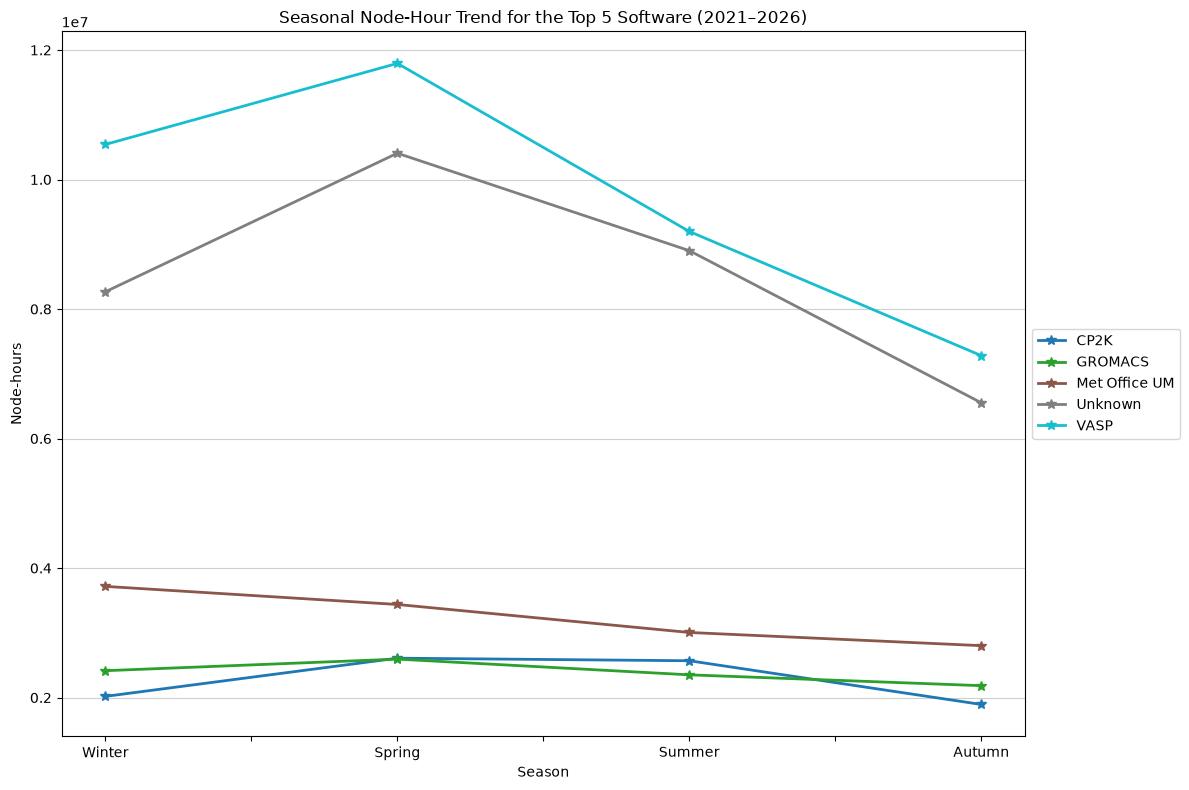

In [9]:
# Plot the seasonal trend across all years
pivot_df.plot(
    kind="line",
    figsize=(12, 8),
    linewidth=2,
    marker="*",
    cmap="tab10",
    markersize=7
)

plt.title("Seasonal Node-Hour Trend for the Top 5 Software (2021–2026)")
plt.xlabel("Season")
plt.ylabel("Node-hours")
plt.grid(axis="y", linestyle="-", alpha=0.6)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

# Seasonal analysis and cumulative seasonal trend views

This section pulls together the seasonal graphing ideas from the original notebook: summary tables per season, cumulative seasonal trends, and a year-by-year seasonal breakdown.


Top 5 software overall:
Software
VASP             38813941.0
Unknown          34127812.1
Met Office UM    12963665.3
GROMACS           9546313.3
CP2K              9091777.7
Name: Nodeh, dtype: float64
Seasonal summary table:
Software       CP2K    GROMACS  Met Office UM     Unknown        VASP
Season                                                               
Winter    2019118.6  2415683.7      3717394.6   8266670.4  10541849.4
Spring    2608972.6  2594441.3      3438179.1  10406381.5  11793326.6
Summer    2569194.1  2351719.2      3005815.5   8901804.0   9198018.8
Autumn    1894492.4  2184469.1      2802276.1   6552956.2   7280746.2


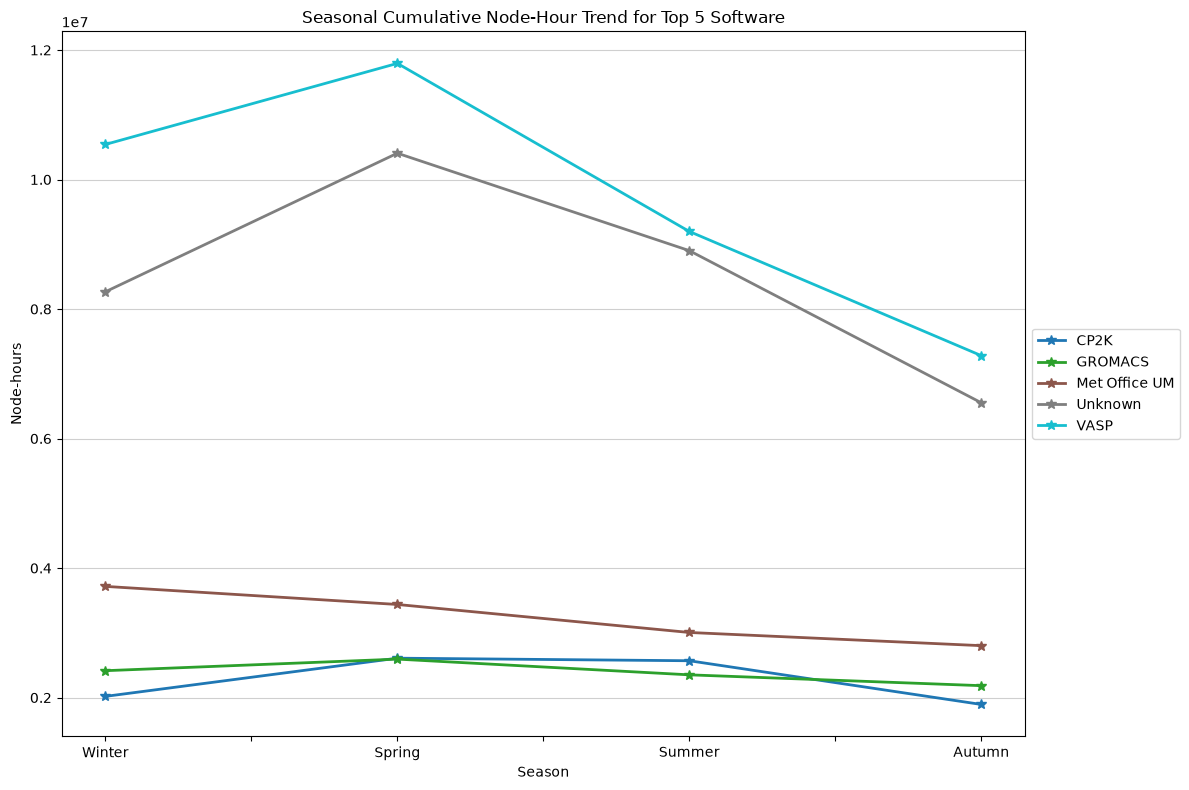

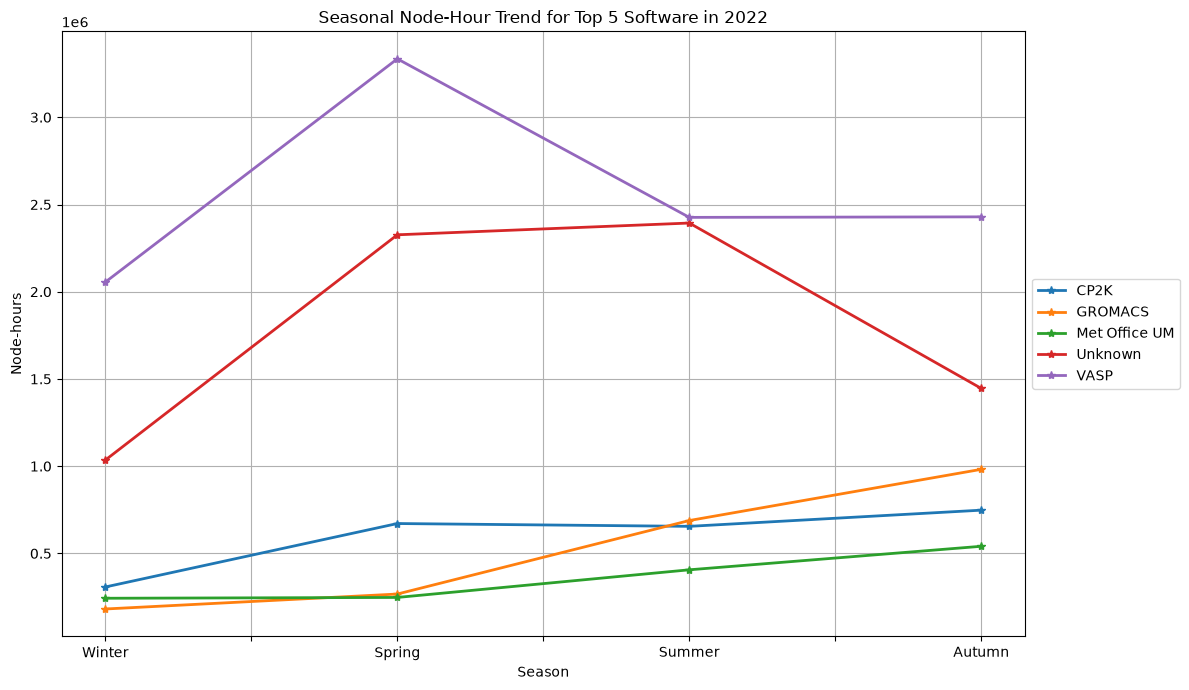

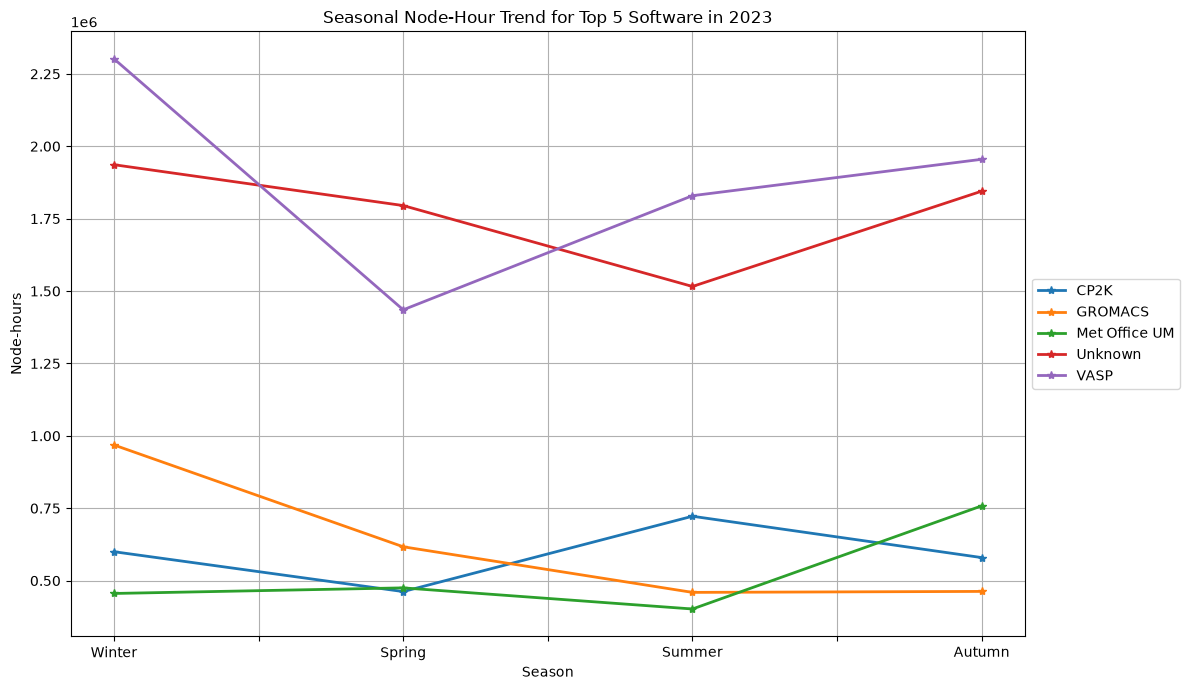

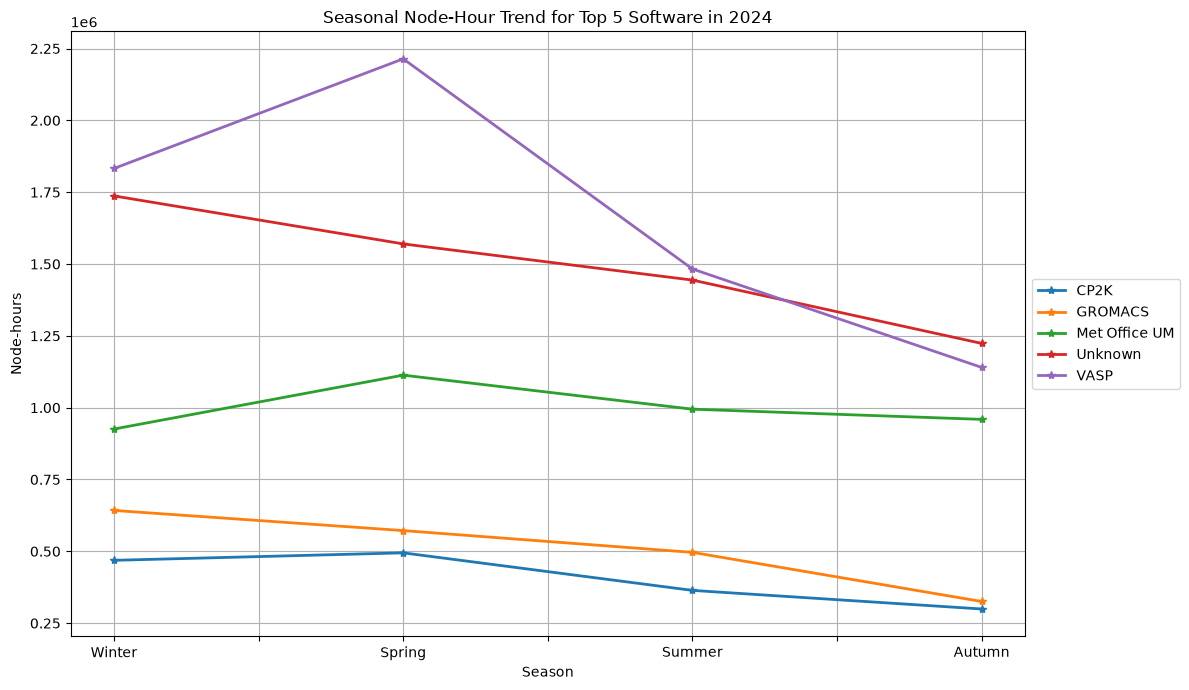

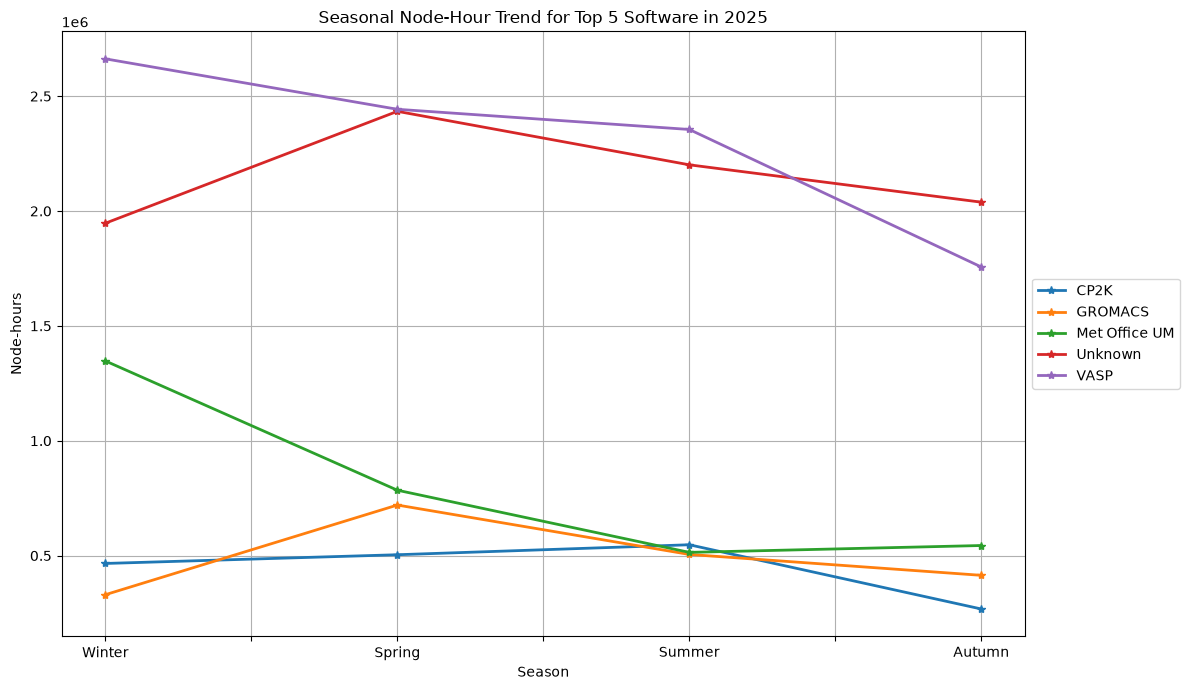

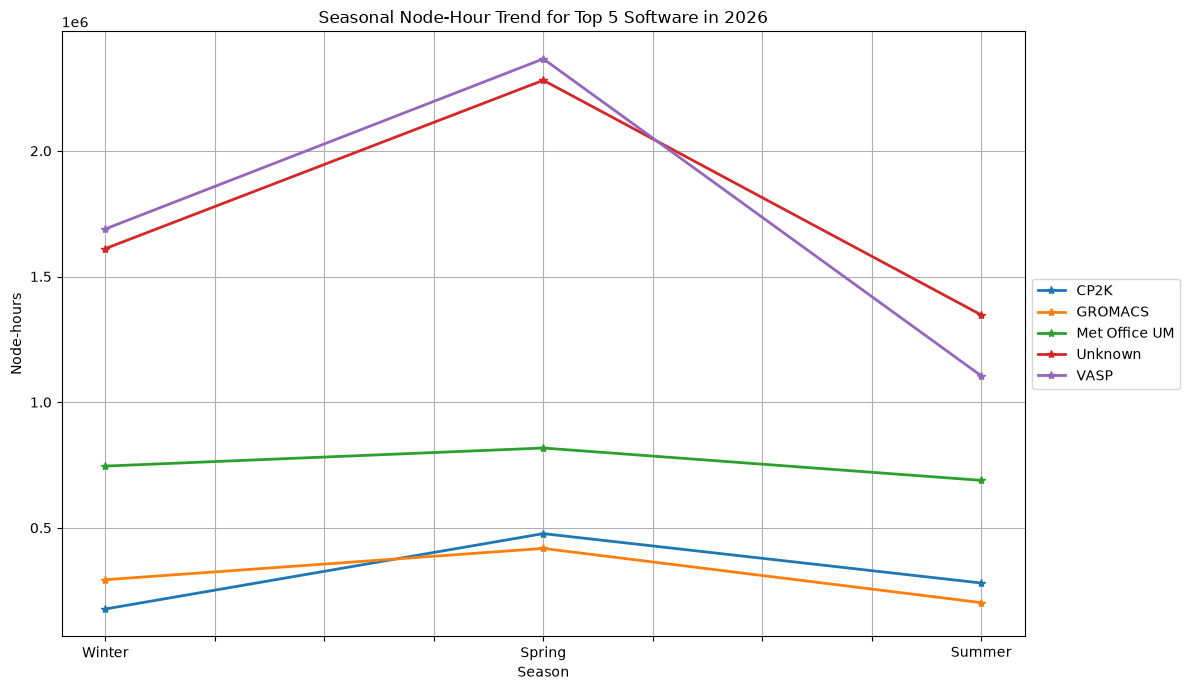

In [10]:
# Seasonal charts from the original graphing notebook
# 1) cumulative seasonal trend across all years
# 2) year-by-year seasonal trend plots
# 3) overall seasonal profile for top software

import pandas as pd
import matplotlib.pyplot as plt

hpc_data = pd.read_csv("../data/archer2_HPC_data_without_overall_and_aOut.csv")

# Clean the data
hpc_data["Year"] = pd.to_numeric(hpc_data["Year"], errors="coerce")
hpc_data["Month"] = pd.to_numeric(hpc_data["Month"], errors="coerce")
hpc_data["Nodeh"] = pd.to_numeric(hpc_data["Nodeh"], errors="coerce").fillna(0)

season_order = ["Winter", "Spring", "Summer", "Autumn"]
hpc_data["Season"] = pd.Categorical(
    hpc_data["Season"],
    categories=season_order,
    ordered=True
)

# Get top 5 software overall
overall_top5 = (
    hpc_data.groupby("Software")["Nodeh"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 software overall:")
print(overall_top5)

selected_software = overall_top5.index.tolist()
filtered = hpc_data[hpc_data["Software"].isin(selected_software)]

# Cumulative seasonal totals over all years
seasonal_trend = (
    filtered.groupby(["Season", "Software"], observed=True)["Nodeh"]
    .sum()
    .reset_index()
)

pivot_df = seasonal_trend.pivot_table(
    index="Season",
    columns="Software",
    values="Nodeh",
    aggfunc="sum",
    observed=True
).fillna(0)

pivot_df = pivot_df.reindex(season_order)
print("Seasonal summary table:")
print(pivot_df)

# Plot cumulative seasonal trend across all years
pivot_df.plot(
    kind="line",
    figsize=(12, 8),
    linewidth=2,
    marker="*",
    cmap="tab10",
    markersize=7
)

plt.title("Seasonal Cumulative Node-Hour Trend for Top 5 Software")
plt.xlabel("Season")
plt.ylabel("Node-hours")
plt.grid(axis="y", linestyle="-", alpha=0.6)
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

# Year-by-year seasonal trend plots
for year_name, year_group in filtered.groupby("Year"):
    yearly_seasonal = (
        year_group.groupby(["Season", "Software"], observed=True)["Nodeh"]
        .sum()
        .reset_index()
    )

    pivot_year = yearly_seasonal.pivot_table(
        index="Season",
        columns="Software",
        values="Nodeh",
        aggfunc="sum",
        observed=True
    ).fillna(0)

    pivot_year = pivot_year.reindex(season_order)

    fig, ax = plt.subplots(figsize=(12, 7))
    pivot_year.plot(kind="line", ax=ax, marker="*", linewidth=2)
    ax.set_title(f"Seasonal Node-Hour Trend for Top 5 Software in {int(year_name)}")
    ax.set_xlabel("Season")
    ax.set_ylabel("Node-hours")
    ax.grid(True)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    plt.tight_layout()
    plt.show()
